Predictive Modeling for Early Gestational Diabetes Mellitus(GDM) Risk Detection Using Clinical and Demographic Data.

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [8]:
data = pd.read_excel("C:/Users/Admin/OneDrive - Sol Plaatje University/Documents/capstone project/Gestational Diabetic Dat Set.xlsx")


In [9]:
data.head()

,Case Number,Age,No of Pregnancy,Gestation in previous Pregnancy,BMI,HDL,Family History,unexplained prenetal loss,Large Child or Birth Default,PCOS,Sys BP,Dia BP,OGTT,Hemoglobin,Sedentary Lifestyle,Prediabetes,Class Label(GDM /Non GDM)
0,1,22,2,1,NaN,55.0,0,0,0,0,102.0,69,NaN,12.0,0,0,0
1,2,26,2,1,NaN,53.0,0,0,0,0,101.0,63,NaN,12.4,0,0,0
2,3,29,1,0,NaN,50.0,0,0,0,0,118.0,79,NaN,14.3,0,0,0
3,4,28,2,1,NaN,51.0,0,0,0,0,99.0,70,NaN,15.0,0,0,0
4,5,21,2,1,NaN,52.0,0,0,0,0,116.0,65,NaN,15.0,0,0,0


In [10]:
print("Dataset shape:", data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)

Dataset shape: (3525, 17)

Column names:
['Case Number', 'Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'HDL', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'PCOS', 'Sys BP', 'Dia BP', 'OGTT', 'Hemoglobin', 'Sedentary Lifestyle', 'Prediabetes', 'Class Label(GDM /Non GDM)']

Data types:
Case Number                          int64
Age                                  int64
No of Pregnancy                      int64
Gestation in previous Pregnancy      int64
BMI                                float64
HDL                                float64
Family History                       int64
unexplained prenetal loss            int64
Large Child or Birth Default         int64
PCOS                                 int64
Sys BP                             float64
Dia BP                               int64
OGTT                               float64
Hemoglobin                         float64
Sedentary Lifestyle                  int64
Prediabetes   

In [11]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
Case Number                           0
Age                                   0
No of Pregnancy                       0
Gestation in previous Pregnancy       0
BMI                                1081
HDL                                1001
Family History                        0
unexplained prenetal loss             0
Large Child or Birth Default          0
PCOS                                  0
Sys BP                             1705
Dia BP                                0
OGTT                                513
Hemoglobin                            0
Sedentary Lifestyle                   0
Prediabetes                           0
Class Label(GDM /Non GDM)             0
dtype: int64


In [12]:
print("Number of duplicated rows:",
      data.duplicated().sum())

Number of duplicated rows: 0


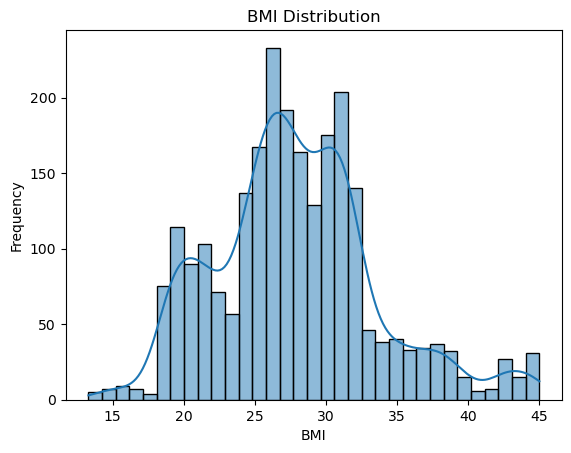

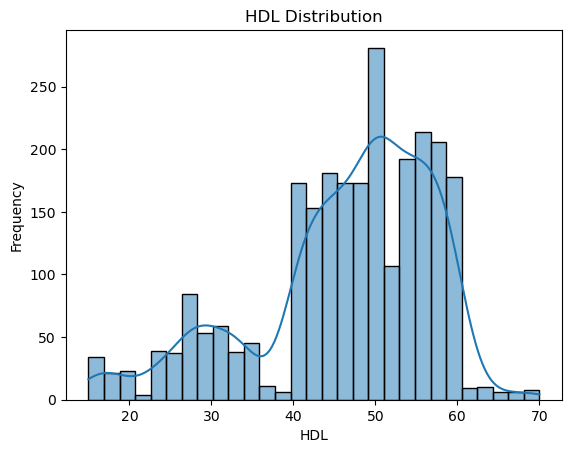

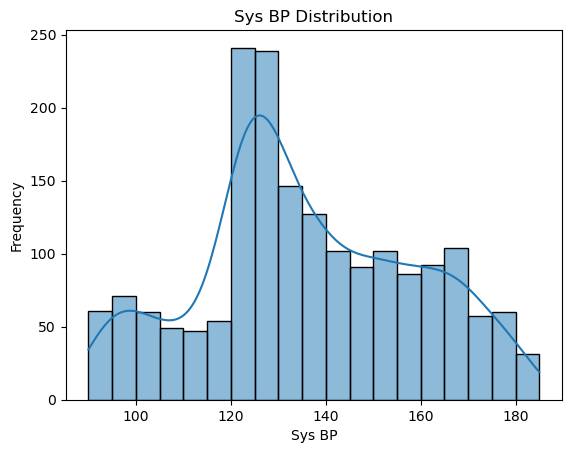

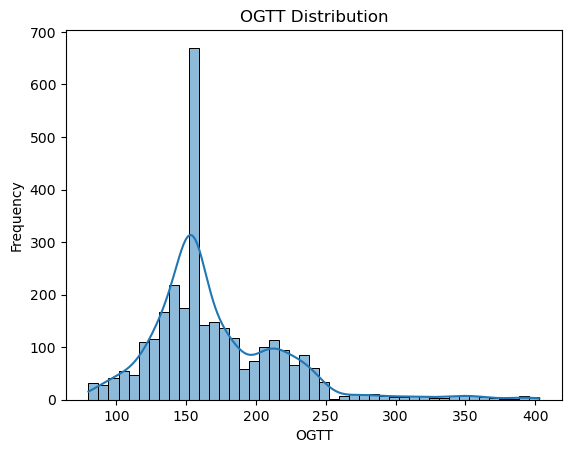

In [14]:
columns = ['BMI', 'HDL', 'Sys BP', 'OGTT']

for col in columns:
    sns.histplot(data[col], kde=True)
    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [15]:
for col in columns:
    print(f"{col}: Skewness = {data[col].skew():.2f}")

BMI: Skewness = 0.52
HDL: Skewness = -0.92
Sys BP: Skewness = 0.09
OGTT: Skewness = 1.50


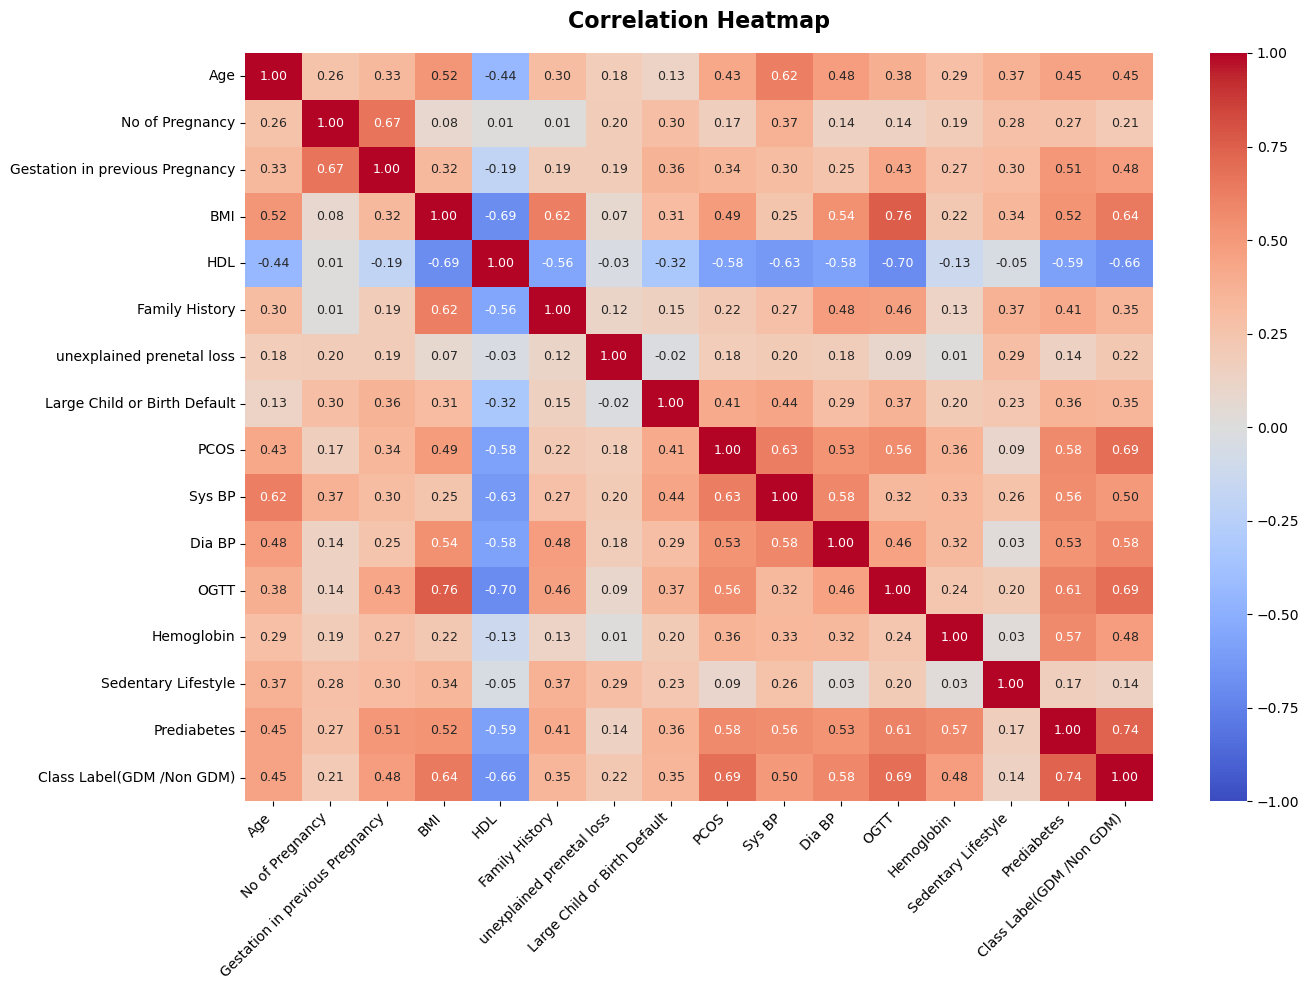

In [16]:
clean_data = data.drop(columns=['Case Number']).select_dtypes(include='number')

corr_matrix = clean_data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1,
    vmax=1,
    annot_kws={"size": 9}
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.title(
    'Correlation Heatmap',
    fontsize=16,
    fontweight='bold',
    pad=18
)

plt.tight_layout()
plt.show()

In [17]:
numerical_cols = [
    'Age',
    'BMI',
    'HDL',
    'Sys BP',
    'Dia BP',
    'OGTT',
    'Hemoglobin'
]

for col in numerical_cols:

    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower) |
        (data[col] > upper)
    ]

    print(f"{col}: {len(outliers)} outliers")

Age: 0 outliers
BMI: 88 outliers
HDL: 82 outliers
Sys BP: 0 outliers
Dia BP: 163 outliers
OGTT: 104 outliers
Hemoglobin: 6 outliers


In [18]:
data[['BMI', 'HDL', 'Sys BP', 'Dia BP', 'OGTT']].describe()

,BMI,HDL,Sys BP,Dia BP,OGTT
count,2444.000000,2524.000000,1820.000000,3525.000000,3012.000000
mean,27.854092,46.471870,135.762088,81.538156,170.707503
std,5.714737,10.800813,22.742844,11.379758,48.160549
min,13.300000,15.000000,90.000000,60.000000,80.000000
25%,24.400000,42.000000,122.000000,74.000000,142.000000
50%,27.500000,49.000000,132.000000,81.000000,156.000000
75%,31.000000,55.000000,153.000000,86.000000,195.000000
max,45.000000,70.000000,185.000000,124.000000,403.000000


# TRAIN-TEST SPLITTING

## Experiment 1: All Features

This experiment uses all available predictor variables, including OGTT and Prediabetes.

In [19]:
X1 = data.drop(
    [
        'Case Number',
        'Class Label(GDM /Non GDM)'
    ],
    axis=1
)

y1 = data['Class Label(GDM /Non GDM)']

In [20]:
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1,
    y1,
    test_size=0.2,
    random_state=100,
    stratify=y1
)

print("Training set:", X1_train.shape)
print("Testing set:", X1_test.shape)

Training set: (2820, 15)
Testing set: (705, 15)


## Experiment 2: Without OGTT and Prediabetes

This experiment excludes OGTT and Prediabetes to investigate model performance using the remaining clinical and demographic variables.

In [21]:
X2 = data.drop(
    [
        'Case Number',
        'Class Label(GDM /Non GDM)',
        'OGTT',
        'Prediabetes'
    ],
    axis=1
)

y2 = data['Class Label(GDM /Non GDM)']

In [22]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.2,
    random_state=100,
    stratify=y2
)

print("Training set:", X2_train.shape)
print("Testing set:", X2_test.shape)

Training set: (2820, 13)
Testing set: (705, 13)


In [23]:
imputation_columns = ['BMI', 'HDL', 'Sys BP', 'OGTT']

mean_columns = []
median_columns = []

for col in imputation_columns:

    skewness = X1_train[col].skew()

    print(f"{col}: training skewness = {skewness:.2f}")

    if -0.5 <= skewness <= 0.5:
        mean_columns.append(col)
        print(f"{col}: Mean imputation")
    else:
        median_columns.append(col)
        print(f"{col}: Median imputation")

BMI: training skewness = 0.53
BMI: Median imputation
HDL: training skewness = -0.93
HDL: Median imputation
Sys BP: training skewness = 0.10
Sys BP: Mean imputation
OGTT: training skewness = 1.52
OGTT: Median imputation


# RANDOM FOREST

## Experiment 1: All Features

In [24]:
mean_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean'))
])

median_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor_rf1 = ColumnTransformer(
    transformers=[
        ('mean', mean_transformer, mean_columns),
        ('median', median_transformer, median_columns)
    ],
    remainder='passthrough'
)

In [25]:
rf1 = Pipeline([
    ('preprocessing', preprocessor_rf1),

    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=100
    ))
])

In [26]:
rf1.fit(X1_train, y1_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('mean',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['Sys BP']),
                                                 ('median',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['BMI', 'HDL', 'OGTT'])])),
                ('model',
                 RandomForestClassifier(max_depth=8, min_samples_leaf=5,
                                        min_samples_split=10,
                                        random_state=100))])

In [27]:
y_rf1_train_pred = rf1.predict(X1_train)
y_rf1_test_pred = rf1.predict(X1_test)

In [28]:
print("Training Accuracy:",
      accuracy_score(y1_train, y_rf1_train_pred))

print("Testing Accuracy:",
      accuracy_score(y1_test, y_rf1_test_pred))

Training Accuracy: 0.9868794326241135
Testing Accuracy: 0.9673758865248226


In [29]:
print("Classification Report - Random Forest Experiment 1")

print(
    classification_report(
        y1_test,
        y_rf1_test_pred
    )
)

Classification Report - Random Forest Experiment 1
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       431
           1       0.95      0.97      0.96       274

    accuracy                           0.97       705
   macro avg       0.96      0.97      0.97       705
weighted avg       0.97      0.97      0.97       705



[[416  15]
 [  8 266]]


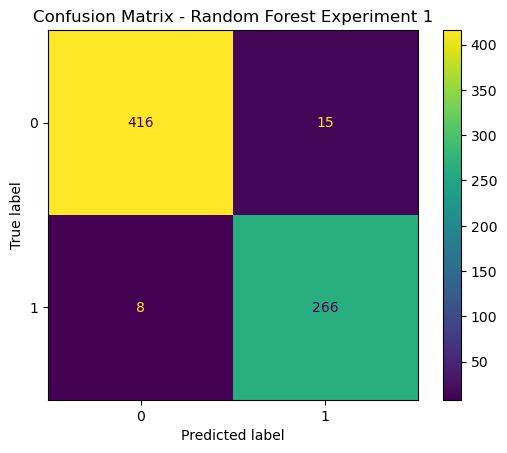

In [30]:
cm_rf1 = confusion_matrix(
    y1_test,
    y_rf1_test_pred
)

print(cm_rf1)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf1
).plot()

plt.title("Confusion Matrix - Random Forest Experiment 1")
plt.show()

In [31]:
y_rf1_prob = rf1.predict_proba(X1_test)[:, 1]

rf1_auc = roc_auc_score(
    y1_test,
    y_rf1_prob
)

print("ROC-AUC:", rf1_auc)

ROC-AUC: 0.9982048198892407


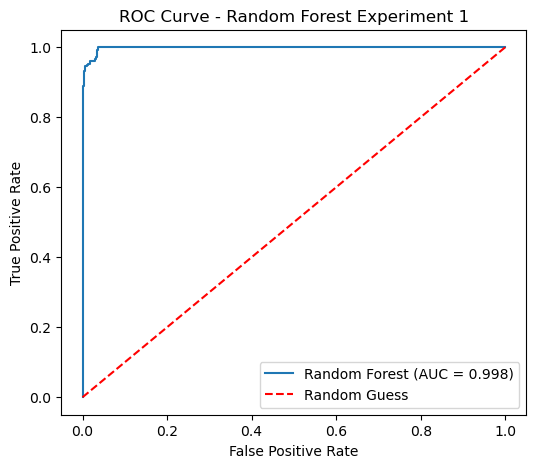

In [32]:
fpr_rf1, tpr_rf1, thresholds_rf1 = roc_curve(
    y1_test,
    y_rf1_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_rf1,
    tpr_rf1,
    label=f'Random Forest (AUC = {rf1_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    'r--',
    label='Random Guess'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest Experiment 1")
plt.legend()

plt.show()

In [33]:
cv_scores_rf1 = cross_val_score(
    rf1,
    X1_train,
    y1_train,
    cv=5,
    scoring='accuracy'
)

print("Cross-validation scores:")
print(cv_scores_rf1)

print(
    "Mean CV Accuracy:",
    cv_scores_rf1.mean()
)

Cross-validation scores:
[0.96276596 0.9751773  0.9787234  0.96985816 0.9751773 ]
Mean CV Accuracy: 0.9723404255319149


## Experiment 2: Without OGTT and Prediabetes

In [34]:
imputation_columns2 = [
    'BMI',
    'HDL',
    'Sys BP'
]

In [35]:
mean_columns2 = []
median_columns2 = []

for col in imputation_columns2:

    skewness = X2_train[col].skew()

    print(f"{col}: training skewness = {skewness:.2f}")

    if -0.5 <= skewness <= 0.5:
        mean_columns2.append(col)
        print(f"{col}: Mean imputation")
    else:
        median_columns2.append(col)
        print(f"{col}: Median imputation")

BMI: training skewness = 0.53
BMI: Median imputation
HDL: training skewness = -0.93
HDL: Median imputation
Sys BP: training skewness = 0.10
Sys BP: Mean imputation


In [36]:
mean_transformer2 = Pipeline([
    ('imputer', SimpleImputer(strategy='mean'))
])

median_transformer2 = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor_rf2 = ColumnTransformer(
    transformers=[
        ('mean', mean_transformer2, mean_columns2),
        ('median', median_transformer2, median_columns2)
    ],
    remainder='passthrough'
)

In [37]:
rf2 = Pipeline([
    ('preprocessing', preprocessor_rf2),

    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=100
    ))
])



In [38]:
rf2.fit(X2_train, y2_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('mean',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['Sys BP']),
                                                 ('median',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['BMI', 'HDL'])])),
                ('model',
                 RandomForestClassifier(max_depth=8, min_samples_leaf=5,
                                        min_samples_split=10,
                                        random_state=100))])

In [39]:
y_rf2_train_pred = rf2.predict(X2_train)
y_rf2_test_pred = rf2.predict(X2_test)

print("Training Accuracy:",
      accuracy_score(y2_train, y_rf2_train_pred))

print("Testing Accuracy:",
      accuracy_score(y2_test, y_rf2_test_pred))

Training Accuracy: 0.9829787234042553
Testing Accuracy: 0.9673758865248226


In [40]:
print("Classification Report - Random Forest Experiment 2")

print(
    classification_report(
        y2_test,
        y_rf2_test_pred
    )
)

Classification Report - Random Forest Experiment 2
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       431
           1       0.95      0.97      0.96       274

    accuracy                           0.97       705
   macro avg       0.96      0.97      0.97       705
weighted avg       0.97      0.97      0.97       705



[[416  15]
 [  8 266]]


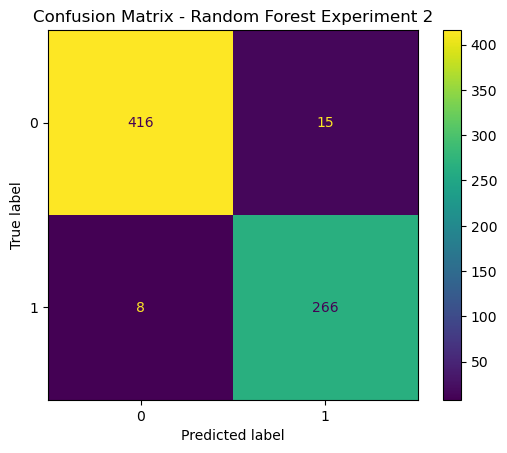

In [41]:
cm_rf2 = confusion_matrix(
    y2_test,
    y_rf2_test_pred
)

print(cm_rf2)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf2
).plot()

plt.title("Confusion Matrix - Random Forest Experiment 2")
plt.show()

In [42]:
y_rf2_prob = rf2.predict_proba(X2_test)[:, 1]

rf2_auc = roc_auc_score(
    y2_test,
    y_rf2_prob
)

print("ROC-AUC:", rf2_auc)

ROC-AUC: 0.9982217555506631


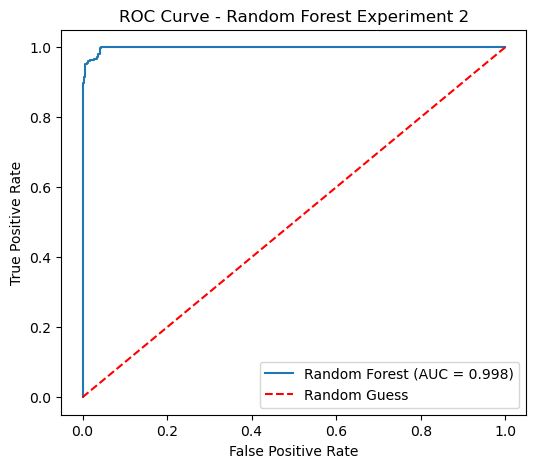

In [43]:
fpr_rf2, tpr_rf2, thresholds_rf2 = roc_curve(
    y2_test,
    y_rf2_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_rf2,
    tpr_rf2,
    label=f'Random Forest (AUC = {rf2_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    'r--',
    label='Random Guess'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest Experiment 2")
plt.legend()

plt.show()

In [44]:
cv_scores_rf2 = cross_val_score(
    rf2,
    X2_train,
    y2_train,
    cv=5,
    scoring='accuracy'
)

print("Cross-validation scores:")
print(cv_scores_rf2)

print(
    "Mean CV Accuracy:",
    cv_scores_rf2.mean()
)

Cross-validation scores:
[0.96453901 0.9787234  0.97695035 0.97695035 0.98049645]
Mean CV Accuracy: 0.975531914893617


# LOGISTIC REGRESSION

## Experiment 1: All Features

In [45]:
preprocessor_lr1 = ColumnTransformer(
    transformers=[
        ('mean', SimpleImputer(strategy='mean'), mean_columns),
        ('median', SimpleImputer(strategy='median'), median_columns)
    ],
    remainder='passthrough'
)

In [46]:
lr1 = Pipeline([
    ('preprocessing', preprocessor_lr1),

    ('scaler', StandardScaler()),

    ('model', LogisticRegression(
        max_iter=1000,
        random_state=100
    ))
])

In [47]:
lr1.fit(X1_train, y1_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('mean', SimpleImputer(),
                                                  ['Sys BP']),
                                                 ('median',
                                                  SimpleImputer(strategy='median'),
                                                  ['BMI', 'HDL', 'OGTT'])])),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=100))])

In [48]:
y_lr1_train_pred = lr1.predict(X1_train)
y_lr1_test_pred = lr1.predict(X1_test)

print("Training Accuracy:",
      accuracy_score(y1_train, y_lr1_train_pred))

print("Testing Accuracy:",
      accuracy_score(y1_test, y_lr1_test_pred))

Training Accuracy: 0.9705673758865249
Testing Accuracy: 0.9687943262411347


In [49]:
print("Classification Report - Logistic Regression Experiment 1")

print(
    classification_report(
        y1_test,
        y_lr1_test_pred
    )
)

Classification Report - Logistic Regression Experiment 1
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       431
           1       0.95      0.97      0.96       274

    accuracy                           0.97       705
   macro avg       0.97      0.97      0.97       705
weighted avg       0.97      0.97      0.97       705



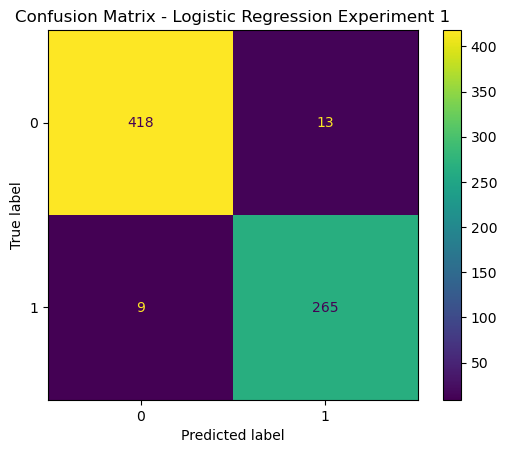

In [50]:
cm_lr1 = confusion_matrix(
    y1_test,
    y_lr1_test_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr1
).plot()

plt.title(
    "Confusion Matrix - Logistic Regression Experiment 1"
)

plt.show()

In [51]:
y_lr1_prob = lr1.predict_proba(X1_test)[:, 1]

lr1_auc = roc_auc_score(
    y1_test,
    y_lr1_prob
)

print("ROC-AUC:", lr1_auc)

ROC-AUC: 0.9914220874896269


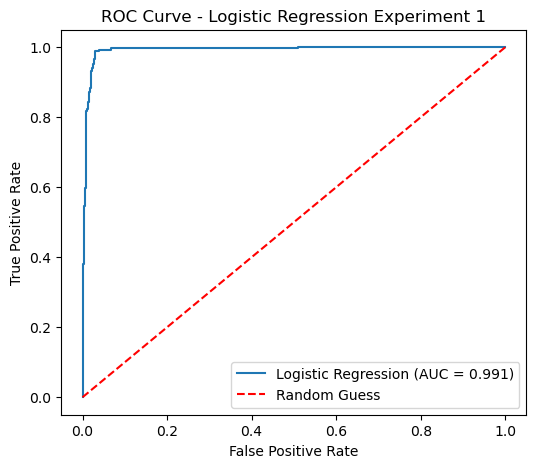

In [52]:
fpr_lr1, tpr_lr1, thresholds_lr1 = roc_curve(
    y1_test,
    y_lr1_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_lr1,
    tpr_lr1,
    label=f'Logistic Regression (AUC = {lr1_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    'r--',
    label='Random Guess'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Logistic Regression Experiment 1"
)

plt.legend()
plt.show()

In [53]:
cv_scores_lr1 = cross_val_score(
    lr1,
    X1_train,
    y1_train,
    cv=5,
    scoring='accuracy'
)

print("Cross-validation scores:")
print(cv_scores_lr1)

print(
    "Mean CV Accuracy:",
    cv_scores_lr1.mean()
)


Cross-validation scores:
[0.96808511 0.98049645 0.96808511 0.96099291 0.97163121]
Mean CV Accuracy: 0.9698581560283689


## Experiment 2: Without OGTT and Prediabetes

In [54]:
preprocessor_lr2 = ColumnTransformer(
    transformers=[
        ('mean', SimpleImputer(strategy='mean'), mean_columns2),
        ('median', SimpleImputer(strategy='median'), median_columns2)
    ],
    remainder='passthrough'
)

In [55]:
lr2 = Pipeline([
    ('preprocessing', preprocessor_lr2),

    ('scaler', StandardScaler()),

    ('model', LogisticRegression(
        max_iter=1000,
        random_state=100
    ))
])

In [56]:
lr2.fit(X2_train, y2_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('mean', SimpleImputer(),
                                                  ['Sys BP']),
                                                 ('median',
                                                  SimpleImputer(strategy='median'),
                                                  ['BMI', 'HDL'])])),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=100))])

In [57]:
y_lr2_train_pred = lr2.predict(X2_train)
y_lr2_test_pred = lr2.predict(X2_test)

print("Training Accuracy:",
      accuracy_score(y2_train, y_lr2_train_pred))

print("Testing Accuracy:",
      accuracy_score(y2_test, y_lr2_test_pred))

Training Accuracy: 0.9599290780141844
Testing Accuracy: 0.9588652482269504


In [58]:
print("Classification Report - Logistic Regression Experiment 2")

print(
    classification_report(
        y2_test,
        y_lr2_test_pred
    )
)

Classification Report - Logistic Regression Experiment 2
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       431
           1       0.96      0.94      0.95       274

    accuracy                           0.96       705
   macro avg       0.96      0.96      0.96       705
weighted avg       0.96      0.96      0.96       705



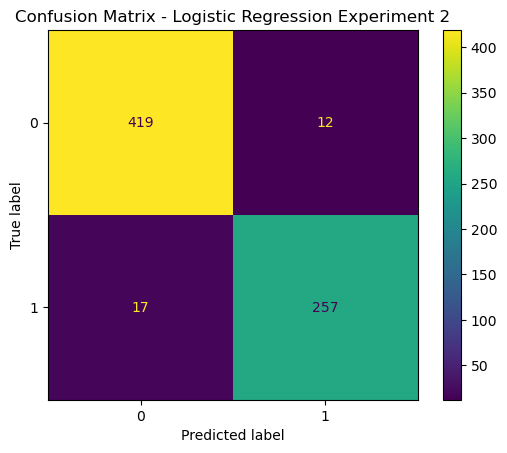

In [59]:
cm_lr2 = confusion_matrix(
    y2_test,
    y_lr2_test_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr2
).plot()

plt.title(
    "Confusion Matrix - Logistic Regression Experiment 2"
)

plt.show()

In [60]:
y_lr2_prob = lr2.predict_proba(X2_test)[:, 1]

lr2_auc = roc_auc_score(
    y2_test,
    y_lr2_prob
)

print("ROC-AUC:", lr2_auc)

ROC-AUC: 0.9737073856419463


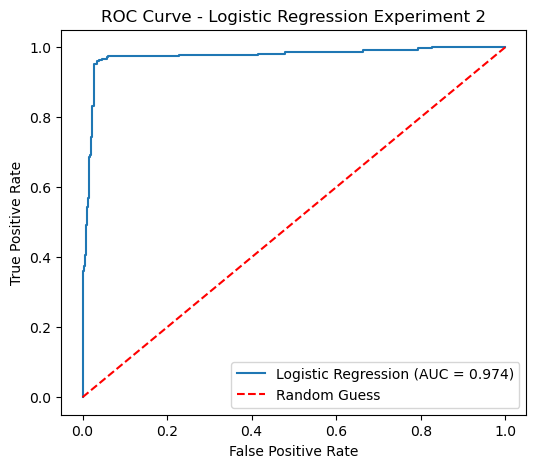

In [61]:
fpr_lr2, tpr_lr2, thresholds_lr2 = roc_curve(
    y2_test,
    y_lr2_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr_lr2,
    tpr_lr2,
    label=f'Logistic Regression (AUC = {lr2_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    'r--',
    label='Random Guess'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Logistic Regression Experiment 2"
)

plt.legend()
plt.show()

In [62]:
cv_scores_lr2 = cross_val_score(
    lr2,
    X2_train,
    y2_train,
    cv=5,
    scoring='accuracy'
)

print("Cross-validation scores:")
print(cv_scores_lr2)

print(
    "Mean CV Accuracy:",
    cv_scores_lr2.mean()
)

Cross-validation scores:
[0.94858156 0.96985816 0.95744681 0.95744681 0.97163121]
Mean CV Accuracy: 0.9609929078014184


In [64]:
feature_names_lr1 = (
    mean_columns +
    median_columns +
    [
        col for col in X1.columns
        if col not in mean_columns + median_columns
    ]
)

coefficients_lr1 = lr1.named_steps['model'].coef_[0]

odds_ratios_lr1 = pd.DataFrame({
    'Feature': feature_names_lr1,
    'Coefficient': coefficients_lr1,
    'Odds Ratio': np.exp(coefficients_lr1)
})

print(
    odds_ratios_lr1.sort_values(
        by='Odds Ratio',
        ascending=False
    )
)

                            Feature  Coefficient  Odds Ratio
3                              OGTT     3.151574   23.372827
10                             PCOS     1.813990    6.134880
14                      Prediabetes     1.049675    2.856722
8         unexplained prenetal loss     0.826767    2.285917
12                       Hemoglobin     0.792712    2.209380
11                           Dia BP     0.486696    1.626932
6   Gestation in previous Pregnancy     0.420664    1.522972
7                    Family History     0.379225    1.461152
9      Large Child or Birth Default     0.145828    1.156998
1                               BMI     0.128155    1.136729
4                               Age     0.072546    1.075242
2                               HDL    -0.001289    0.998712
13              Sedentary Lifestyle    -0.069930    0.932459
5                   No of Pregnancy    -0.181607    0.833929
0                            Sys BP    -0.670340    0.511535


In [65]:
feature_names_lr2 = (
    mean_columns2 +
    median_columns2 +
    [
        col for col in X2.columns
        if col not in mean_columns2 + median_columns2
    ]
)

coefficients_lr2 = lr2.named_steps['model'].coef_[0]

odds_ratios_lr2 = pd.DataFrame({
    'Feature': feature_names_lr2,
    'Coefficient': coefficients_lr2,
    'Odds Ratio': np.exp(coefficients_lr2)
})

print(
    odds_ratios_lr2.sort_values(
        by='Odds Ratio',
        ascending=False
    )
)

                            Feature  Coefficient  Odds Ratio
9                              PCOS     1.991572    7.327045
1                               BMI     1.484985    4.414897
11                       Hemoglobin     1.224155    3.401291
5   Gestation in previous Pregnancy     1.088500    2.969816
7         unexplained prenetal loss     0.862080    2.368081
6                    Family History     0.726179    2.067166
10                           Dia BP     0.633076    1.883395
3                               Age     0.595691    1.814284
8      Large Child or Birth Default     0.427316    1.533137
2                               HDL     0.003388    1.003393
12              Sedentary Lifestyle    -0.264345    0.767708
4                   No of Pregnancy    -0.476568    0.620911
0                            Sys BP    -0.982742    0.374284


In [ ]:
# MODEL COMPARISON

In [66]:
results = pd.DataFrame({
    'Algorithm': [
        'Random Forest',
        'Random Forest',
        'Logistic Regression',
        'Logistic Regression'
    ],

    'Experiment': [
        'All Features',
        'Without OGTT & Prediabetes',
        'All Features',
        'Without OGTT & Prediabetes'
    ],

    'Test Accuracy': [
        accuracy_score(y1_test, y_rf1_test_pred),
        accuracy_score(y2_test, y_rf2_test_pred),
        accuracy_score(y1_test, y_lr1_test_pred),
        accuracy_score(y2_test, y_lr2_test_pred)
    ],

    'ROC-AUC': [
        rf1_auc,
        rf2_auc,
        lr1_auc,
        lr2_auc
    ],

    'Mean CV Accuracy': [
        cv_scores_rf1.mean(),
        cv_scores_rf2.mean(),
        cv_scores_lr1.mean(),
        cv_scores_lr2.mean()
    ]
})

print(results)

             Algorithm                  Experiment  Test Accuracy   ROC-AUC  \
0        Random Forest                All Features       0.967376  0.998205   
1        Random Forest  Without OGTT & Prediabetes       0.967376  0.998222   
2  Logistic Regression                All Features       0.968794  0.991422   
3  Logistic Regression  Without OGTT & Prediabetes       0.958865  0.973707   

   Mean CV Accuracy  
0          0.972340  
1          0.975532  
2          0.969858  
3          0.960993  
